# As I don't know derivatives and algebra, I am unable to understand the mathematical intution behind weights initialization with various activation functions. So here I'm just going through coding session

# Here, first of all we'll learn what not to do and then will learn the correct methods of weights initialization.


# `Case 1`: Zero initialization with relu activation function.
We should never initialize weights to zero while using relu activation function bcz it doesn't update the weights during back propogation and keeps zero for the entire training. Let's see it practically.

In [283]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dropout, Dense

In [284]:
from sklearn.datasets import make_circles

In [285]:
x, y = make_circles(n_samples = 100, noise = 0.1, random_state = 1)

In [286]:
x[0:5]

array([[-0.63640493, -0.36870191],
       [-0.24465976, -0.73659196],
       [-0.46597138, -1.06687743],
       [-0.70999784, -0.40841948],
       [ 0.70232238, -0.51730147]])

In [287]:
y[0:5]

array([1, 1, 0, 1, 1], dtype=int64)

In [288]:
df = pd.DataFrame(data = x, columns = ['Feature1', 'Feature2'])
df['Label'] = y

In [289]:
df.head()

,Feature1,Feature2,Label
0,-0.636405,-0.368702,1
1,-0.244660,-0.736592,1
2,-0.465971,-1.066877,0
3,-0.709998,-0.408419,1
4,0.702322,-0.517301,1


<AxesSubplot: xlabel='Feature1', ylabel='Feature2'>

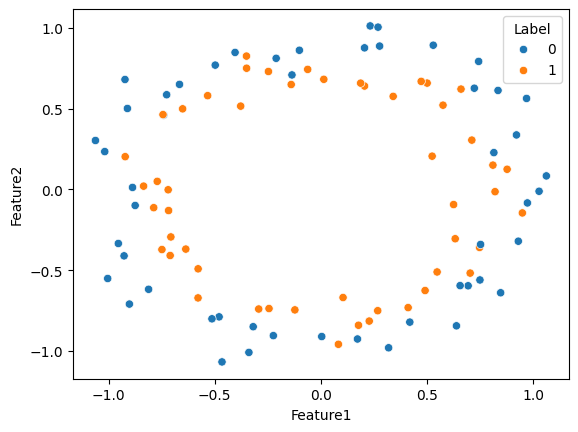

In [290]:
import seaborn as sns

sns.scatterplot(df, x = 'Feature1', y = 'Feature2', hue = 'Label')

In [291]:
# Train_test_split

from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 2)


In [308]:
x_train

array([[ 0.31843503, -0.97937344],
       [ 0.17181003, -0.92504802],
       [-0.92263395,  0.68059245],
       [-0.57877973, -0.67082245],
       [-0.06259331,  0.7430852 ],
       [-0.49776571,  0.76955129],
       [-0.33930852, -1.0080984 ],
       [-0.37799331,  0.51586893],
       [ 0.74218942,  0.79243568],
       [-0.74376426,  0.46339773],
       [ 0.22716539, -0.81418053],
       [-0.24465976, -0.73659196],
       [-0.74875324, -0.37153443],
       [-0.87474347, -0.09886802],
       [ 0.92901189, -0.31993308],
       [-0.29317877, -0.73949777],
       [-0.31914906, -0.84899624],
       [-0.71940931, -0.00172619],
       [-0.40443454,  0.84799759],
       [ 0.41030774, -0.73075986],
       [ 0.65917045,  0.62120588],
       [ 0.96779554,  0.56332827],
       [ 0.72182595,  0.62661863],
       [ 0.49980305,  0.65833135],
       [-0.78743102, -0.11249056],
       [ 0.52327611,  0.20621942],
       [ 0.23161178,  1.01205842],
       [ 0.49009938, -0.62509577],
       [-0.8114891 ,

In [293]:
model1 = Sequential()

model1.add(Dense(2, activation = 'relu', input_dim = 2))
model1.add(Dense(1, activation = 'sigmoid'))

In [294]:
model1.summary()

Model: "sequential_14"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_46 (Dense)            (None, 2)                 6         
                                                                 
 dense_47 (Dense)            (None, 1)                 3         
                                                                 
Total params: 9 (36.00 Byte)
Trainable params: 9 (36.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [204]:
model1.get_weights()

[array([[-1.1987448 , -0.92236143],
        [-0.1924007 , -0.0074352 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.5614685 ],
        [-0.12873805]], dtype=float32),
 array([0.], dtype=float32)]

In [205]:
# Storing initial weights to var initial_weights

initial_weights = model1.get_weights()

# Model1.get_weights()[0]: Gives weights of first layer This will give 2 lists, weights for 1st and 2nd input respectively
# model1.get_weights()[1]: Gives biases of 1st layer

# model1.get_weights()[2]: Gives weights of 2nd layer
# model1.get_weights()[3]: Gives biases of 2nd layer
# and so onn

In [206]:
np.zeros((5,3))

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [207]:
# changing weights of 0th layer t.e the starting weights to zeros.

initial_weights[0] = np.zeros(model1.get_weights()[0].shape)

In [208]:
initial_weights[0]

array([[0., 0.],
       [0., 0.]])

In [209]:
# lly changing weights and biases of all the layers to zero

initial_weights[1] = np.zeros(model1.get_weights()[1].shape)
initial_weights[2] = np.zeros(model1.get_weights()[2].shape)
initial_weights[3] = np.zeros(model1.get_weights()[3].shape)

In [210]:
initial_weights

[array([[0., 0.],
        [0., 0.]]),
 array([0., 0.]),
 array([[0.],
        [0.]]),
 array([0.])]

In [211]:
# Setting the chnaged weights and biases to the model

model1.set_weights(initial_weights)

In [212]:
model1.get_weights()

# We can see, weights and biases are changed to zero

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [213]:
model1.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [295]:
history1 = model1.fit(x_train, y_train, epochs = 100, validation_split = 0.2)

RuntimeError: You must compile your model before training/testing. Use `model.compile(optimizer, loss)`.

In [215]:
model1.get_weights()

# As satated while starting the session, when we initialize weights and biases to zeros with 'relu' activation
# it remains zero till the completion on training. Weights and biases doesn't get update.

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([-0.07271738], dtype=float32)]

9600/9600 [==============================] - 13s 1ms/step


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlxtend\plotting\decision_regions.py:315: UserWarning: No contour levels were found within the data range.
  ax.contour(xx, yy, Z, cset.levels, **contour_kwargs)


<AxesSubplot: >

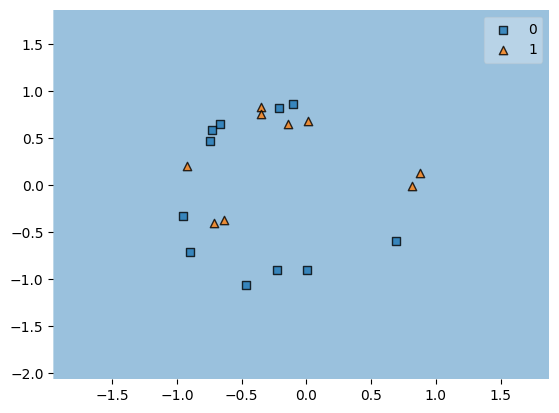

In [218]:
# LEt's see the decision boundry the model has created

from mlxtend.plotting import plot_decision_regions

plot_decision_regions(x_test.values, y_test.values.ravel(), clf = model1, )

9600/9600 [==============================] - 14s 1ms/step


<AxesSubplot: >

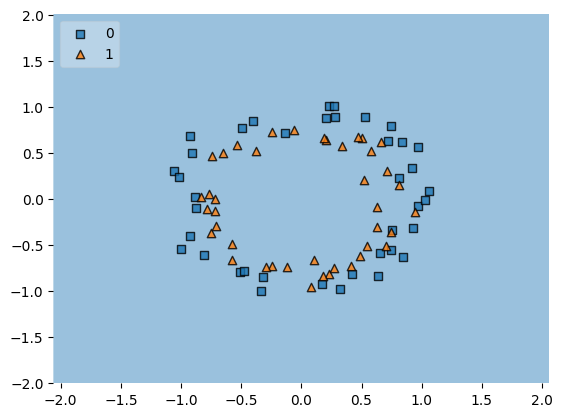

In [219]:
plot_decision_regions(x_train.values, y_train.values.ravel(), clf = model1, legend = 2)

In [220]:
# See, the model is classifying  every points in 0

# Case 2: With `tanh` activation function.

In [221]:
model2 = Sequential()

model2.add(Dense(2, activation = 'tanh', input_dim = 2))
model2.add(Dense(1, activation = 'sigmoid'))

model2.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_30 (Dense)            (None, 2)                 6         
                                                                 
 dense_31 (Dense)            (None, 1)                 3         
                                                                 
Total params: 9 (36.00 Byte)
Trainable params: 9 (36.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [222]:
model2.get_weights()

[array([[-0.23901236, -1.1855886 ],
        [-0.36578208, -0.3720271 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.7356503],
        [-0.7638071]], dtype=float32),
 array([0.], dtype=float32)]

In [223]:
initial_weights = model2.get_weights()

In [224]:
# Changing initial weights and biases to zero

initial_weights[0] = np.zeros(initial_weights[0].shape)
initial_weights[1] = np.zeros(initial_weights[1].shape)
initial_weights[2] = np.zeros(initial_weights[2].shape)
initial_weights[3] = np.zeros(initial_weights[3].shape)

In [225]:
initial_weights

[array([[0., 0.],
        [0., 0.]]),
 array([0., 0.]),
 array([[0.],
        [0.]]),
 array([0.])]

In [226]:
# Setting new weights and biases into the model

model2.set_weights(initial_weights)

In [227]:
model2.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [228]:
model2.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = 'accuracy')

In [229]:
history2 = model2.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 100)

Epoch 1/100
3/3 [==============================] - 1s 128ms/step - loss: 0.6932 - accuracy: 0.4125 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 2/100
3/3 [==============================] - 0s 22ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 3/100
3/3 [==============================] - 0s 22ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 4/100
3/3 [==============================] - 0s 26ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 5/100
3/3 [==============================] - 0s 26ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 6/100
3/3 [==============================] - 0s 25ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 7/100
3/3 [==============================] - 0s 20ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 8/100
3/3 [==

In [230]:
model2.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.03778872], dtype=float32)]

9600/9600 [==============================] - 13s 1ms/step


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlxtend\plotting\decision_regions.py:315: UserWarning: No contour levels were found within the data range.
  ax.contour(xx, yy, Z, cset.levels, **contour_kwargs)


<AxesSubplot: >

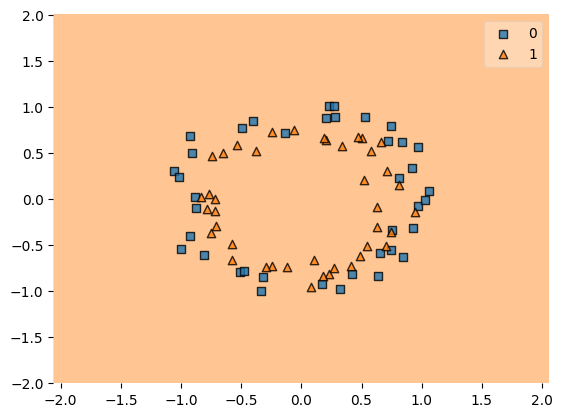

In [231]:
plot_decision_regions(x_train.values, y_train.values.ravel(), clf = model2)

# Classifying every points as 1

# With sigmoid activation:

This will change the weights and biases but the values of weights of each layer will be same and values of biases of each layer will be same

In [232]:
model3 = Sequential()

model3.add(Dense(2, activation = 'sigmoid', input_dim = 2))
model3.add(Dense(1, activation = 'sigmoid'))

model3.summary()

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_32 (Dense)            (None, 2)                 6         
                                                                 
 dense_33 (Dense)            (None, 1)                 3         
                                                                 
Total params: 9 (36.00 Byte)
Trainable params: 9 (36.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [233]:
model3.get_weights()

[array([[ 0.17978704, -1.1967919 ],
        [ 0.36111176, -0.84528136]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[1.118364 ],
        [1.0153943]], dtype=float32),
 array([0.], dtype=float32)]

In [234]:
initial_weights = model3.get_weights()

In [235]:
# Changing initial weights and biases to zero

initial_weights[0] = np.zeros(initial_weights[0].shape)
initial_weights[1] = np.zeros(initial_weights[1].shape)
initial_weights[2] = np.zeros(initial_weights[2].shape)
initial_weights[3] = np.zeros(initial_weights[3].shape)

In [236]:
initial_weights

[array([[0., 0.],
        [0., 0.]]),
 array([0., 0.]),
 array([[0.],
        [0.]]),
 array([0.])]

In [237]:
# Setting new weights and biases into the model

model3.set_weights(initial_weights)

In [238]:
model3.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [239]:
model3.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = 'accuracy')

In [240]:
history3 = model3.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 100)

Epoch 1/100
3/3 [==============================] - 1s 126ms/step - loss: 0.6932 - accuracy: 0.4875 - val_loss: 0.6931 - val_accuracy: 0.5500
Epoch 2/100
3/3 [==============================] - 0s 23ms/step - loss: 0.6932 - accuracy: 0.4875 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 3/100
3/3 [==============================] - 0s 24ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 4/100
3/3 [==============================] - 0s 22ms/step - loss: 0.6932 - accuracy: 0.5125 - val_loss: 0.6934 - val_accuracy: 0.4500
Epoch 5/100
3/3 [==============================] - 0s 19ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6934 - val_accuracy: 0.4500
Epoch 6/100
3/3 [==============================] - 0s 21ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6934 - val_accuracy: 0.4500
Epoch 7/100
3/3 [==============================] - 0s 23ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6935 - val_accuracy: 0.4500
Epoch 8/100
3/3 [==

In [52]:
model3.get_weights()

# We can see that the weights and biases for each node is same.

[array([[-1.2931224, -1.2931224],
        [-0.9361074, -0.9361074]], dtype=float32),
 array([0.09877837, 0.09877837], dtype=float32),
 array([[-0.7557779],
        [-0.7557779]], dtype=float32),
 array([-0.06737451], dtype=float32)]

9600/9600 [==============================] - 13s 1ms/step


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlxtend\plotting\decision_regions.py:315: UserWarning: No contour levels were found within the data range.
  ax.contour(xx, yy, Z, cset.levels, **contour_kwargs)


<AxesSubplot: >

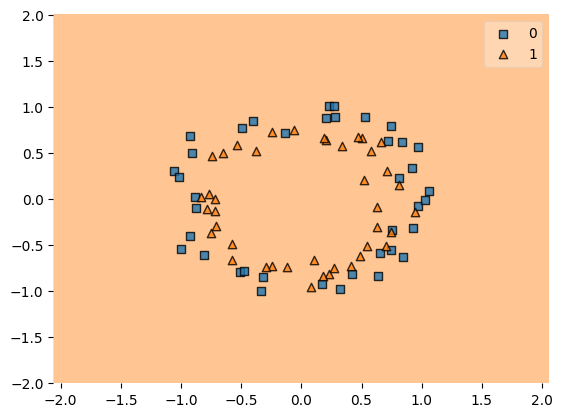

In [241]:
plot_decision_regions(x_train.values, y_train.values.ravel(), clf = model3)

# Classifying every points as 1

# Non-zero number: 
`For example: 0.5`
This will act like zero with sigmoid, irrespective of activation function. Will keep values of weights and biases of each layer same.
Will act as a linear model. Will make linear decision boundry

In [242]:
model4 = Sequential()

model4.add(Dense(5, activation = 'relu', input_dim = 2))
model4.add(Dense(1, activation = 'sigmoid'))

model4.summary()

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_34 (Dense)            (None, 5)                 15        
                                                                 
 dense_35 (Dense)            (None, 1)                 6         
                                                                 
Total params: 21 (84.00 Byte)
Trainable params: 21 (84.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [243]:
model4.get_weights()

[array([[-0.8552375 ,  0.465356  , -0.24556339, -0.26832932,  0.24810398],
        [ 0.44051743,  0.4205091 , -0.12625647, -0.36633086,  0.48148715]],
       dtype=float32),
 array([0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.36842537],
        [-0.1716578 ],
        [-0.1267662 ],
        [ 0.8422468 ],
        [ 0.93487215]], dtype=float32),
 array([0.], dtype=float32)]

In [244]:
initial_weights = model4.get_weights()

In [245]:
np.ones((2,3))

array([[1., 1., 1.],
       [1., 1., 1.]])

In [246]:
# Changing initial weights and biases to zero

initial_weights[0] = np.ones(initial_weights[0].shape) * 0.5
initial_weights[1] = np.ones(initial_weights[1].shape) * 0.5
initial_weights[2] = np.ones(initial_weights[2].shape) * 0.5
initial_weights[3] = np.ones(initial_weights[3].shape) * 0.5

In [247]:
# Setting new weights and biases into the model

model4.set_weights(initial_weights)

In [248]:
model4.get_weights()

[array([[0.5, 0.5, 0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5, 0.5, 0.5]], dtype=float32),
 array([0.5, 0.5, 0.5, 0.5, 0.5], dtype=float32),
 array([[0.5],
        [0.5],
        [0.5],
        [0.5],
        [0.5]], dtype=float32),
 array([0.5], dtype=float32)]

In [249]:
model4.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = 'accuracy')

In [250]:
history4 = model4.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 100)

Epoch 1/100
3/3 [==============================] - 1s 120ms/step - loss: 1.1761 - accuracy: 0.5125 - val_loss: 0.9622 - val_accuracy: 0.4500
Epoch 2/100
3/3 [==============================] - 0s 26ms/step - loss: 1.1687 - accuracy: 0.5125 - val_loss: 0.9574 - val_accuracy: 0.4500
Epoch 3/100
3/3 [==============================] - 0s 22ms/step - loss: 1.1611 - accuracy: 0.5125 - val_loss: 0.9527 - val_accuracy: 0.4500
Epoch 4/100
3/3 [==============================] - 0s 22ms/step - loss: 1.1540 - accuracy: 0.5125 - val_loss: 0.9479 - val_accuracy: 0.4500
Epoch 5/100
3/3 [==============================] - 0s 21ms/step - loss: 1.1473 - accuracy: 0.5125 - val_loss: 0.9433 - val_accuracy: 0.4500
Epoch 6/100
3/3 [==============================] - 0s 22ms/step - loss: 1.1395 - accuracy: 0.5125 - val_loss: 0.9389 - val_accuracy: 0.4500
Epoch 7/100
3/3 [==============================] - 0s 22ms/step - loss: 1.1330 - accuracy: 0.5125 - val_loss: 0.9345 - val_accuracy: 0.4500
Epoch 8/100
3/3 [==

In [251]:
model4.get_weights()

# As stated earlier, it will change weights and biases of each layer with same value.

[array([[0.2947755 , 0.2947755 , 0.2947755 , 0.2947755 , 0.2947755 ],
        [0.29597437, 0.29597437, 0.29597437, 0.29597437, 0.29597437]],
       dtype=float32),
 array([0.29218, 0.29218, 0.29218, 0.29218, 0.29218], dtype=float32),
 array([[0.28046483],
        [0.28046483],
        [0.28046483],
        [0.28046483],
        [0.28046483]], dtype=float32),
 array([0.2570818], dtype=float32)]

9600/9600 [==============================] - 13s 1ms/step


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlxtend\plotting\decision_regions.py:315: UserWarning: No contour levels were found within the data range.
  ax.contour(xx, yy, Z, cset.levels, **contour_kwargs)


<AxesSubplot: >

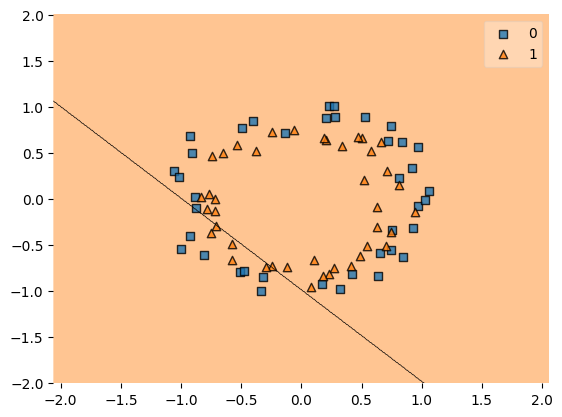

In [252]:
plot_decision_regions(x_train.values, y_train.values.ravel(), clf = model4)

# Acting as a linear model

# Now we know, we should never initialize weights and biases as zero or any non-zero as well.
# Now let's see what should we do.

# What if we go for `random_initialization.`

`Random initialization` means we don't initialize weights and biases with any particular value, insted we initialize weights of each layer with some random value.

Here we are applying `random_initialization` with `tanh` activation fuction.

# `Case 1`: Initializing very small random number.

In [253]:
model5 = Sequential()

In [254]:
model5.add(Dense(2, activation = 'tanh', input_dim = 2))
model5.add(Dense(2, activation = 'tanh'))
model5.add(Dense(2, activation = 'tanh'))
model5.add(Dense(2, activation = 'tanh'))
model5.add(Dense(1, activation = 'sigmoid'))

model5.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_36 (Dense)            (None, 2)                 6         
                                                                 
 dense_37 (Dense)            (None, 2)                 6         
                                                                 
 dense_38 (Dense)            (None, 2)                 6         
                                                                 
 dense_39 (Dense)            (None, 2)                 6         
                                                                 
 dense_40 (Dense)            (None, 1)                 3         
                                                                 
Total params: 27 (108.00 Byte)
Trainable params: 27 (108.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [255]:
model5.get_weights()

[array([[ 0.3440194 , -0.14755619],
        [ 0.08601558,  0.50017834]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.69093674, -1.2149769 ],
        [-0.7511916 , -0.3973431 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.6768091 , -0.38294888],
        [ 0.61799264,  0.7170093 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.5419024 ,  0.6307945 ],
        [-0.05371284, -0.18083131]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 1.1224822],
        [-0.3116672]], dtype=float32),
 array([0.], dtype=float32)]

In [256]:
initial_weights = model5.get_weights()

In [257]:
np.random.randint(0,5, (2,2))

array([[2, 2],
       [0, 1]])

In [258]:
np.random.randn(2,5)

array([[-0.35403984,  1.35612993, -0.84695232,  0.54701009,  1.79406118],
       [-1.58286345, -0.06992118,  0.78214541,  0.23894647, -0.63482403]])

In [259]:
np.random.randn(initial_weights[0].shape[0], initial_weights[0].shape[1] )

array([[-0.18099466,  0.18576976],
       [-2.19846588,  0.32141386]])

In [260]:
initial_weights[0][0]

array([ 0.3440194 , -0.14755619], dtype=float32)

In [261]:
initial_weights[0] = np.random.randn(initial_weights[0].shape[0], initial_weights[0].shape[1]) * 0.01    # Weights of 1st layer
initial_weights[1] = np.zeros(initial_weights[1].shape)    # Biases of 1st layer as zero

initial_weights[2] = np.random.randn(initial_weights[2].shape[0], initial_weights[2].shape[1]) * 0.01
initial_weights[3] = np.zeros(initial_weights[3].shape)    # Biases of 2na layer as zero

initial_weights[4] = np.random.randn(initial_weights[4].shape[0], initial_weights[4].shape[1]) * 0.01
initial_weights[5] = np.zeros(initial_weights[5].shape)    # Biases of 3rd layer as zero

initial_weights[6] = np.random.randn(initial_weights[6].shape[0], initial_weights[6].shape[1]) * 0.01
initial_weights[7] = np.zeros(initial_weights[7].shape)    # Biases of 4th layer as zero

initial_weights[8] = np.random.randn(initial_weights[8].shape[0], initial_weights[8].shape[1]) * 0.01
initial_weights[9] = np.zeros(initial_weights[9].shape)    # Biases of 5th layer as zero


# Here, we are only initializing weights of each layer with random number
# And initializing biases of each layer as zero

In [262]:
initial_weights

[array([[ 0.01351151, -0.00114501],
        [ 0.01014148, -0.00024378]]),
 array([0., 0.]),
 array([[-0.00064733,  0.00928641],
        [ 0.00373141,  0.00930008]]),
 array([0., 0.]),
 array([[ 0.00346194,  0.00918326],
        [-0.01167987,  0.00021294]]),
 array([0., 0.]),
 array([[-0.00511853,  0.0028519 ],
        [ 0.00675732,  0.00380999]]),
 array([0., 0.]),
 array([[-0.01202169],
        [ 0.01015126]]),
 array([0.])]

In [263]:
# Setting new weights

model5.set_weights(initial_weights)

In [264]:
model5.get_weights()

[array([[ 0.01351151, -0.00114501],
        [ 0.01014148, -0.00024378]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.00064733,  0.00928641],
        [ 0.00373141,  0.00930008]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.00346194,  0.00918326],
        [-0.01167987,  0.00021294]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.00511853,  0.0028519 ],
        [ 0.00675732,  0.00380999]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.01202169],
        [ 0.01015126]], dtype=float32),
 array([0.], dtype=float32)]

In [265]:
model5.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [266]:
history5 = model5.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 100)

Epoch 1/100
3/3 [==============================] - 1s 132ms/step - loss: 0.6932 - accuracy: 0.4875 - val_loss: 0.6931 - val_accuracy: 0.5500
Epoch 2/100
3/3 [==============================] - 0s 21ms/step - loss: 0.6932 - accuracy: 0.4625 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 3/100
3/3 [==============================] - 0s 26ms/step - loss: 0.6932 - accuracy: 0.5125 - val_loss: 0.6932 - val_accuracy: 0.4500
Epoch 4/100
3/3 [==============================] - 0s 20ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 5/100
3/3 [==============================] - 0s 28ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 6/100
3/3 [==============================] - 0s 21ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 7/100
3/3 [==============================] - 0s 25ms/step - loss: 0.6931 - accuracy: 0.5125 - val_loss: 0.6933 - val_accuracy: 0.4500
Epoch 8/100
3/3 [==

In [268]:
model5.get_weights()

[array([[0.02801689, 0.00811338],
        [0.03100491, 0.01244868]], dtype=float32),
 array([-0.00340785, -0.00202576], dtype=float32),
 array([[0.01127465, 0.03738276],
        [0.00654836, 0.01660607]], dtype=float32),
 array([-0.01067958, -0.01968974], dtype=float32),
 array([[-0.00447796,  0.01664766],
        [-0.02808911,  0.01581671]], dtype=float32),
 array([ 0.03678521, -0.03607883], dtype=float32),
 array([[-0.03869352,  0.03621203],
        [ 0.04009252, -0.02926648]], dtype=float32),
 array([-0.03501443,  0.03546105], dtype=float32),
 array([[-0.04448537],
        [ 0.04261266]], dtype=float32),
 array([0.02937577], dtype=float32)]

In [ ]:
# When we initialize very small random weights, it should not get updated these much, but I don't know how
# weights are updating these much and model is working as a linear model.

9600/9600 [==============================] - 14s 1ms/step


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlxtend\plotting\decision_regions.py:315: UserWarning: No contour levels were found within the data range.
  ax.contour(xx, yy, Z, cset.levels, **contour_kwargs)


<AxesSubplot: >

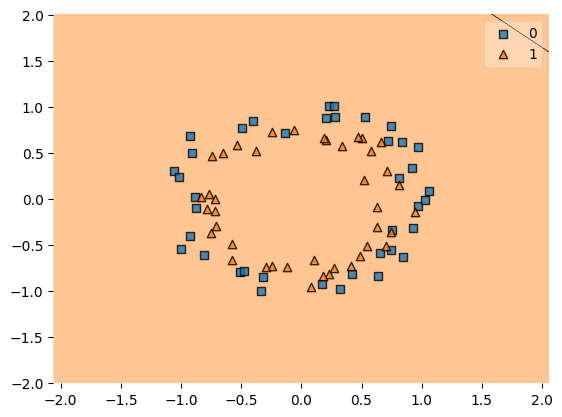

In [267]:
plot_decision_regions(x_train.values, y_train.values.ravel(), clf = model5)

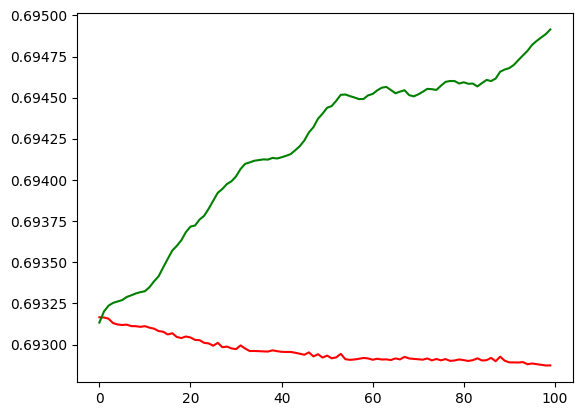

In [269]:
plt.plot(history5.history['loss'], color = 'red')
plt.plot(history5.history['val_loss'], color = 'green')


# `Case 2`: `tanh` with very high random initial weights

This will work but will take many epochs to converge. 100 is not suffecient

In [296]:
model6 = Sequential()

In [297]:
model6.add(Dense(2, activation = 'tanh', input_dim = 2))
model6.add(Dense(2, activation = 'tanh'))
model6.add(Dense(2, activation = 'tanh'))
model6.add(Dense(2, activation = 'tanh'))
model6.add(Dense(1, activation = 'sigmoid'))

model6.summary()

Model: "sequential_15"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_48 (Dense)            (None, 2)                 6         
                                                                 
 dense_49 (Dense)            (None, 2)                 6         
                                                                 
 dense_50 (Dense)            (None, 2)                 6         
                                                                 
 dense_51 (Dense)            (None, 2)                 6         
                                                                 
 dense_52 (Dense)            (None, 1)                 3         
                                                                 
Total params: 27 (108.00 Byte)
Trainable params: 27 (108.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [298]:
model6.get_weights()

[array([[ 0.18748772, -0.19574821],
        [-0.02363634, -0.6421365 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 1.1553525, -0.2136327],
        [-0.5497071, -0.930854 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.95265925,  0.21754527],
        [-0.5756564 , -0.2405302 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.03833747, -0.27985376],
        [ 0.76870036, -1.2051773 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.7858917],
        [ 1.3059782]], dtype=float32),
 array([0.], dtype=float32)]

In [299]:
initial_weights = model6.get_weights()

In [300]:
np.random.randn(2,2) * 1000

array([[  154.65737971, -1905.85611433],
       [ -709.70866042,  -692.75866807]])

In [301]:
initial_weights[0] = np.random.randn(initial_weights[0].shape[0], initial_weights[0].shape[1])  # Weights of 1st layer
initial_weights[1] = np.zeros(initial_weights[1].shape)    # Biases of 1st layer as zero

initial_weights[2] = np.random.randn(initial_weights[2].shape[0], initial_weights[2].shape[1])
initial_weights[3] = np.zeros(initial_weights[3].shape)    # Biases of 2na layer as zero

initial_weights[4] = np.random.randn(initial_weights[4].shape[0], initial_weights[4].shape[1])
initial_weights[5] = np.zeros(initial_weights[5].shape)    # Biases of 3rd layer as zero

initial_weights[6] = np.random.randn(initial_weights[6].shape[0], initial_weights[6].shape[1])
initial_weights[7] = np.zeros(initial_weights[7].shape)    # Biases of 4th layer as zero

initial_weights[8] = np.random.randn(initial_weights[8].shape[0], initial_weights[8].shape[1])
initial_weights[9] = np.zeros(initial_weights[9].shape)    # Biases of 5th layer as zero


# Here, we are only initializing weights of each layer with random number
# And initializing biases of each layer as zero

In [302]:
initial_weights

[array([[ 1.31717845, -1.30186757],
        [-1.25613836, -0.73970131]]),
 array([0., 0.]),
 array([[ 0.06030883, -1.45606346],
        [ 1.02883426,  0.60279508]]),
 array([0., 0.]),
 array([[-0.28898957, -1.82703873],
        [ 0.07056791,  0.06989166]]),
 array([0., 0.]),
 array([[ 0.09854312, -0.22452672],
        [-0.31214105, -1.84657203]]),
 array([0., 0.]),
 array([[-1.38176145],
        [-1.0543448 ]]),
 array([0.])]

In [303]:
# Setting new weights

model6.set_weights(initial_weights)

In [304]:
model6.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [305]:
history6 = model6.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 100)

Epoch 1/100
3/3 [==============================] - 2s 141ms/step - loss: 0.9155 - accuracy: 0.4375 - val_loss: 0.6347 - val_accuracy: 0.7000
Epoch 2/100
3/3 [==============================] - 0s 25ms/step - loss: 0.9123 - accuracy: 0.4375 - val_loss: 0.6343 - val_accuracy: 0.7000
Epoch 3/100
3/3 [==============================] - 0s 27ms/step - loss: 0.9093 - accuracy: 0.4375 - val_loss: 0.6338 - val_accuracy: 0.7000
Epoch 4/100
3/3 [==============================] - 0s 24ms/step - loss: 0.9064 - accuracy: 0.4375 - val_loss: 0.6333 - val_accuracy: 0.7000
Epoch 5/100
3/3 [==============================] - 0s 25ms/step - loss: 0.9038 - accuracy: 0.4375 - val_loss: 0.6329 - val_accuracy: 0.7000
Epoch 6/100
3/3 [==============================] - 0s 22ms/step - loss: 0.9007 - accuracy: 0.4375 - val_loss: 0.6325 - val_accuracy: 0.7000
Epoch 7/100
3/3 [==============================] - 0s 27ms/step - loss: 0.8979 - accuracy: 0.4375 - val_loss: 0.6321 - val_accuracy: 0.7000
Epoch 8/100
3/3 [==

In [306]:
model6.get_weights()

[array([[ 1.556519  , -1.1910404 ],
        [-0.9238107 , -0.62441635]], dtype=float32),
 array([-0.33778724, -0.16943735], dtype=float32),
 array([[ 0.097798  , -1.2262375 ],
        [ 0.7996556 ,  0.95037234]], dtype=float32),
 array([-0.19245097,  0.29513943], dtype=float32),
 array([[-0.57891935, -1.6166847 ],
        [-0.16895837,  0.20946611]], dtype=float32),
 array([0.12871715, 0.18126194], dtype=float32),
 array([[ 0.36898455,  0.0351684 ],
        [-0.1083139 , -1.6451339 ]], dtype=float32),
 array([ 0.08194466, -0.15620144], dtype=float32),
 array([[-1.2881027 ],
        [-0.85281295]], dtype=float32),
 array([-0.08509926], dtype=float32)]

9600/9600 [==============================] - 16s 2ms/step


<AxesSubplot: >

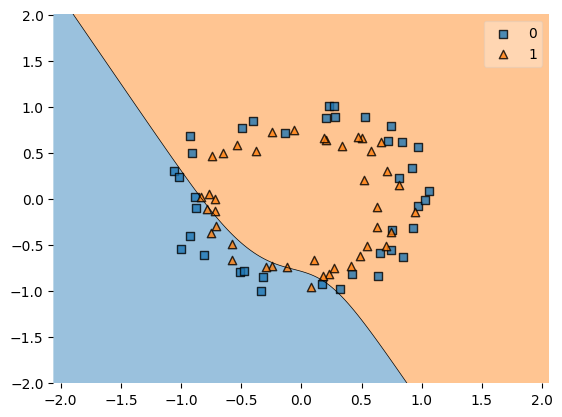

In [310]:
plot_decision_regions(x_train, y_train, clf = model6)